# 01 · Reconhecimento da fonte

Antes de desenhar o pipeline, a pergunta era: **o que muda nos 21 CSVs anuais do SIADE e o que está errado neles?** Este notebook guarda essa investigação. Ele lê as camadas `raw` e `staging`, para mostrar o dado como a ANTT publica, e as decisões que saíram daqui estão no dbt.

In [1]:
import sys; sys.path.insert(0, ".")
from comum import *

## 1. O layout não muda em 21 anos

Todos os anos têm as mesmas 9 colunas, em latin1 com `;`, e números no formato `16.578.555`. A ingestão confere o cabeçalho de cada arquivo e para se ele mudar.

In [2]:
sql("""
select arquivo, linhas, modificado_em
from raw.arquivos_carregados order by arquivo
""")

,arquivo,linhas,modificado_em
0,producao_origem_destino_2006.csv,11499,2026-10-02T21:51:19.179296
1,producao_origem_destino_2007.csv,11356,2026-10-02T21:51:40.400529
2,producao_origem_destino_2008.csv,10791,2026-10-02T21:51:58.170628
3,producao_origem_destino_2009.csv,10077,2026-10-02T21:52:07.710811
4,producao_origem_destino_2010.csv,9467,2026-10-02T21:52:32.098019
5,producao_origem_destino_2011.csv,8784,2026-10-02T21:52:54.992455
6,producao_origem_destino_2012.csv,8493,2026-10-02T21:53:21.884836
7,producao_origem_destino_2013.csv,7962,2026-10-02T21:53:43.001469
8,producao_origem_destino_2014.csv,7278,2026-10-02T21:53:49.383659
9,producao_origem_destino_2015.csv,7082,2026-10-02T21:54:00.221123


O número de linhas cai de 11,5 mil em 2006 para entre 7 e 8 mil desde 2014. São menos combinações de estação e mercadoria, não menos carga. O arquivo do ano corrente é substituído a cada mês publicado; na última carga, ia até agosto de 2026.

## 2. Um mês publicado duas vezes

In [3]:
sql("""
with chaves as (
    select mes_ano, ferrovia, mercadoria, estacao_origem, uf_origem, estacao_destino, uf_destino,
           count(*) as copias, count(distinct (tu, tku)) = 1 as valores_identicos
    from raw.producao
    group by 1, 2, 3, 4, 5, 6, 7
    having count(*) > 1
)
select mes_ano, ferrovia, count(*) as chaves_repetidas, max(copias) as copias_por_chave,
       bool_and(valores_identicos) as todas_identicas
from chaves group by 1, 2
""")

,mes_ano,ferrovia,chaves_repetidas,copias_por_chave,todas_identicas
0,12/2019,RMS,34,2,True


As 34 repetições são todas de dezembro de 2019 da Rumo Malha Sul, com valores idênticos. O `int_producao__deduplicada` remove a cópia. Se aparecer repetição com valores **diferentes**, o teste de chave única do fato para o pipeline, porque aí não há como saber qual das duas vale.

## 3. Onde fica cada estação

O SIADE identifica a estação só pelo nome e pela UF. A primeira tentativa foi o OpenStreetMap, que cobriu só 18% da tonelagem da MRS e casou nomes errados ("Floriano" com Marechal Floriano, no ES). A camada de **pátios declarados pelas concessionárias à ANTT**, publicada pela InfraSA, resolve quase tudo:

In [4]:
sql("""
select coalesce(fonte_coordenada, 'sem coordenada') as fonte,
       count(*) as estacoes,
       round(100.0 * sum(tu_total) / (select sum(tu_total) from intermediate.int_estacoes__geolocalizadas), 2) as pct_carga
from intermediate.int_estacoes__geolocalizadas
group by 1 order by 2 desc
""")

,fonte,estacoes,pct_carga
0,InfraSA,515,99.75
1,"InfraSA, pátio em outra UF",9,0.21
2,sem coordenada,8,0.03
3,"manual: InfraSA, pátio 2109 grafado 'Termnal S...",1,0.01


Três problemas na camada de pátios apareceram aqui:

In [5]:
sql("""
select 'coordenada NaN' as problema, count(*) as patios
from raw.patios where lat = 'NaN' or lon = 'NaN'
""")

,problema,patios
0,coordenada NaN,245


- **245 pátios com coordenada `NaN`.** No Postgres, `NaN` não é nulo: sem o filtro no staging, essas estações contariam como geolocalizadas.
- **UF diferente em estações de divisa.** O SIADE e a InfraSA discordam da UF de estações na divisa entre estados. Sem pátio na mesma UF, vale o de mesmo nome e da mesma ferrovia em outra UF:

In [6]:
sql("""
select e.estacao, e.uf as uf_siade, p.uf as uf_infrasa, e.ferrovia_principal,
       round(e.tu_total / 1e6, 1) as mi_t
from intermediate.int_estacoes__geolocalizadas e
join staging.stg_infrasa__patios p using (patio_id)
where e.fonte_coordenada = 'InfraSA, pátio em outra UF'
order by e.tu_total desc
""")

,estacao,uf_siade,uf_infrasa,ferrovia_principal,mi_t
0,T. Olacyr F. Morais,MS,MT,RMN,23.4
1,Jupia,MS,SP,RMO,10.1
2,São Simão,GO,MG,RMC,7.5
3,Jardim Ingá,GO,DF,FCA,1.1
4,Santa Isabel,TO,GO,RMC,0.2
5,Itabaiana,PB,PE,FTL,0.1
6,Aymores,MG,ES,EFVM,0.1
7,Timon,MA,PI,FTL,0.0
8,Baixio,CE,PB,FTL,0.0


- **Um nome com erro de digitação** ("Termnal Siderúrgico"), que foi para `seeds/estacoes_manuais.csv` com a coordenada da própria InfraSA.

**Como saber se a coordenada está certa?** Pela física: o trilho entre duas estações nunca é mais curto que a linha reta. O teste `assert_linha_reta_nao_passa_da_distancia_ferroviaria` compara as duas para cada rota. Para conferir que ele funciona, a Baía de Sepetiba foi posta em Manaus pelo seed manual, e o teste falhou como deveria.

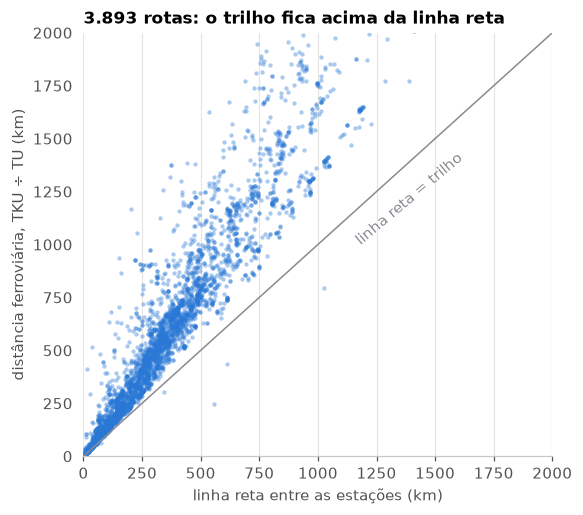

In [7]:
rotas = sql("""
select f.ferrovia, o.estacao as origem, d.estacao as destino, sum(f.tu) as tu,
       sum(f.tku)::numeric / sum(f.tu) as ferroviaria_km,
       st_distancesphere(st_makepoint(o.lon, o.lat), st_makepoint(d.lon, d.lat)) / 1000 as reta_km
from marts.fct_producao_mensal f
join marts.dim_estacoes o on o.estacao_id = f.origem_id and o.geolocalizada
join marts.dim_estacoes d on d.estacao_id = f.destino_id and d.geolocalizada
where f.tu > 0 and f.origem_id <> f.destino_id
group by 1, 2, 3, o.lon, o.lat, d.lon, d.lat
""")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(rotas.reta_km, rotas.ferroviaria_km, s=8, color=AZUL, alpha=0.4, linewidths=0)
ax.plot([0, 2000], [0, 2000], color=CINZA, linewidth=1)
ax.text(1150, 1000, "linha reta = trilho", color=CINZA, rotation=40)
ax.set(xlabel="linha reta entre as estações (km)", ylabel="distância ferroviária, TKU ÷ TU (km)",
       xlim=(0, 2000), ylim=(0, 2000), title=f"{len(rotas):,} rotas: o trilho fica acima da linha reta".replace(",", "."))
ax.grid(axis="both")
plt.show()

## 4. A distância de uma rota deveria ser fixa

TKU ÷ TU dá a distância média do fluxo no mês. Para a mesma origem e o mesmo destino, ela deveria se repetir:

In [8]:
desvio = sql("""
with mediana as (
    select ferrovia, origem_id, destino_id,
           percentile_cont(0.5) within group (order by distancia_km) as mediana_km, count(*) as meses
    from marts.fct_producao_mensal where tu > 0 group by 1, 2, 3
)
select f.tu, abs(f.distancia_km - m.mediana_km) / nullif(m.mediana_km, 0) as desvio
from marts.fct_producao_mensal f join mediana m using (ferrovia, origem_id, destino_id)
where f.tu > 0 and m.meses >= 6
""")
faixas = pd.cut(desvio.desvio, [-0.001, 0.01, 0.05, 0.2, 0.5, float("inf")],
                labels=["até 1%", "1–5%", "5–20%", "20–50%", "mais de 50%"])
(desvio.groupby(faixas, observed=False).tu.sum() / desvio.tu.sum() * 100).round(3).rename("% da carga").to_frame()

,% da carga
desvio,
até 1%,93.324
1–5%,4.520
5–20%,2.056
20–50%,0.067
mais de 50%,0.032


93% da carga fica a menos de 1% da mediana da própria rota. O resíduo acima de 50% é 0,03% da carga, quase tudo erro de digitação em meses isolados, como Intendente Câmara → Curuputuba com 1.198 km em 2006 contra 732 km nos outros meses. Isso não tem como ser corrigido aqui. O teste `assert_distancia_da_rota_estavel` deixa passar esse resíduo e falha se ele passar de 0,5%, o que indicaria TU e TKU trocados ou uma unidade nova num arquivo.

## 5. Uma mercadoria que contradiz o próprio nome

A partir de 2013, a MRS tem uma mercadoria chamada **"Minério de Ferro Especial – MRS distância menor 100 km"**. Até 2017 ela cumpre o nome. Depois, não:

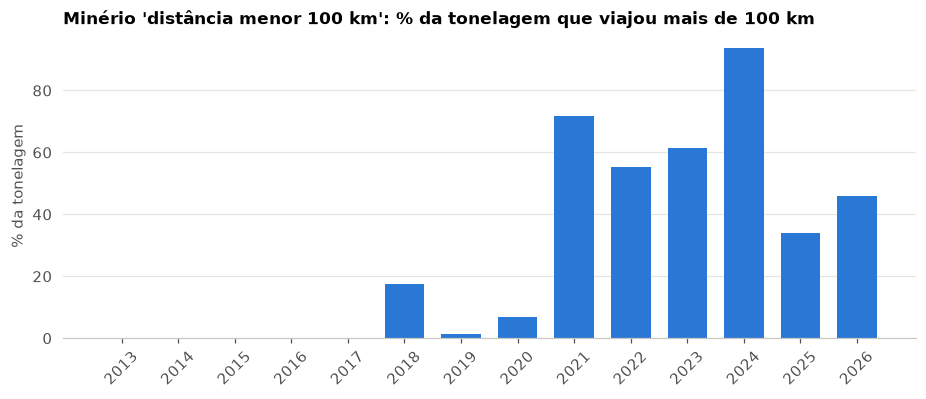

,ano,pct_acima_100km,maior_km
0,2013,NaN,50.1
1,2014,NaN,50.1
2,2015,NaN,9.6
3,2016,NaN,42.0
4,2017,NaN,42.0
5,2018,17.4,130.0
6,2019,1.4,614.4
7,2020,7.0,614.4
8,2021,71.7,460.8
9,2022,55.4,456.4


In [9]:
especial = sql("""
select extract(year from mes)::int as ano,
       sum(tu) filter (where distancia_km > 100) / sum(tu) * 100 as pct_acima_100km,
       max(distancia_km) as maior_km
from marts.fct_producao_mensal
where mercadoria_antt like 'Minério de Ferro Especial%%'
group by 1 order by 1
""")
fig, ax = plt.subplots()
ax.bar(especial.ano, especial.pct_acima_100km.fillna(0), color=AZUL, width=0.7)
ax.set(title="Minério 'distância menor 100 km': % da tonelagem que viajou mais de 100 km", ylabel="% da tonelagem")
ax.set_xticks(especial.ano, especial.ano, rotation=45)
plt.show()
especial.round(1)

Em 2024, 94% da tonelagem dessa categoria viajou mais de 100 km, com fluxos de até 635 km. Uma explicação provável é que a categoria passou a valer para um contrato ou uma tarifa e o nome ficou, mas isso precisa ser confirmado com a ANTT. **Para as análises, não faz diferença:** ela entra em "Minério de ferro" no `seeds/mercadorias.csv`, junto com as outras duas variantes de minério da MRS. A distância nunca é tirada do nome da mercadoria, só de TKU ÷ TU.